# code_022 · Generalization and the target population

**Book:** section 5.1. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_05_GUIDE.md), [execution evidence](../CHAPTER_05_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_022). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=522;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 522


<a id="contract"></a>
## Two prediction contracts

Generate 36 buildings with 24 readings each. In mm, y=.4+1.5*x+b_site+epsilon, with x uniform on [0,1], site offsets sd .65 mm and reading noise sd .08 mm. x is a fixed dimensionless load coordinate. Buildings 0–23 supply 16 training, four development and four final readings each. Buildings 24–29 supply development readings and buildings 30–35 supply final readings. No reading or site outcomes overlap roles. This is a balanced teaching design, not a realistic sampling survey.

The rule fits a shared slope plus one unpenalized intercept per training site by least squares. A known site's fitted intercept is available for future readings; an unseen site receives the mean fitted training-site intercept, with no adaptation. Both are legitimate prediction contracts. A row holdout answers the first, not the second.

**Predict:** can merely removing the site identifier make the hidden site offsets independent? Would calibrating on the new building's outcomes change the contract?


In [2]:
G=36;m=24;site=np.repeat(np.arange(G),m);x=rng.uniform(0,1,G*m)
offset=rng.normal(0,.65,G);y=.4+1.5*x+offset[site]+rng.normal(0,.08,G*m)
reading=np.tile(np.arange(m),G)
train=np.flatnonzero((site<24)&(reading<16));known_dev=np.flatnonzero((site<24)&(reading>=16)&(reading<20));known_final=np.flatnonzero((site<24)&(reading>=20))
new_dev=np.flatnonzero((site>=24)&(site<30));new_final=np.flatnonzero(site>=30)
roles=[train,known_dev,known_final,new_dev,new_final]
assert len(np.unique(np.concatenate(roles)))==G*m
assert not set(site[train])&set(site[new_dev]) and not set(site[train])&set(site[new_final])
A=np.column_stack([x[train],np.eye(24)[site[train]]]);theta=np.linalg.lstsq(A,y[train],rcond=None)[0]
def predict(indices):
 s=site[indices];intercepts=np.full(len(indices),theta[1:].mean());known=s<24
 intercepts[known]=theta[1:][s[known]]
 return theta[0]*x[indices]+intercepts
assert theta.shape==(25,) and np.linalg.norm(A.T@(A@theta-y[train]))<1e-10
assert len(train)==384 and len(known_final)==96 and len(new_final)==144


<a id="development"></a>
## Read development evidence without changing the rule

Report RMSE separately for the two contracts. Equal-sized sites make row-weighted and equal-site mean squared error coincide here. With unequal readings they differ. Prediction uses input site identity only; it never estimates an intercept from development or final targets. The feature transformation x=P/P_ref is fixed, not learned preprocessing.


Development RMSE [mm], known/new: [0.07037735018635698, 0.7809324188664392]


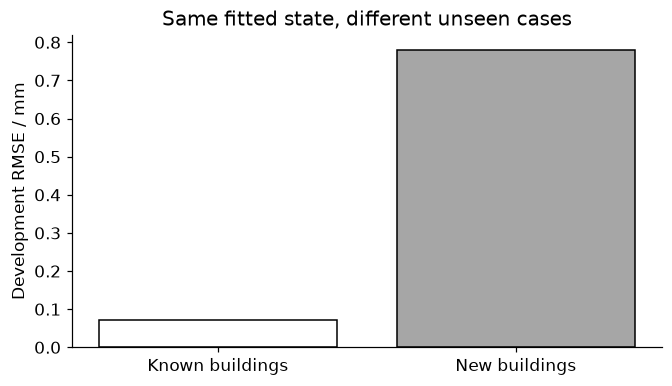

In [3]:
rmse=lambda idx:float(np.sqrt(np.mean((predict(idx)-y[idx])**2)))
dev=[rmse(known_dev),rmse(new_dev)];print('Development RMSE [mm], known/new:',dev)
assert np.isfinite(dev).all()
fig,ax=plt.subplots(figsize=(6,3.4));ax.bar(['Known buildings','New buildings'],dev,color=['white','.65'],edgecolor='black')
ax.set(ylabel='Development RMSE / mm',title='Same fitted state, different unseen cases');plt.show()
RESULTS['development_RMSE_known_new_mm']=dev


<a id="final"></a>
## Open the two final samples once

Settings were fixed before generation. Final scores illustrate this generator only. New-site uncertainty depends principally on six held-out buildings, not 144 independent buildings. No confidence interval treating all rows as independent is claimed. After reading these outcomes, use fresh final sites for model redesign.


In [4]:
final_scores=[rmse(known_final),rmse(new_final)]
site_mse=np.array([np.mean((predict(new_final[site[new_final]==g])-y[new_final[site[new_final]==g]])**2) for g in range(30,36)])
assert np.isclose(np.mean(site_mse),final_scores[1]**2)
assert set(site[new_final])==set(range(30,36)) and np.isfinite(site_mse).all()
print('Final RMSE [mm], known/new:',final_scores)
RESULTS['final_RMSE_known_new_mm']=final_scores;RESULTS['final_new_buildings']=6


Final RMSE [mm], known/new: [0.0811412695481926, 0.7891573160864884]


<a id="support"></a>
## Marginal range is weaker than joint support

A separate constructed feature cloud lies near (load,temperature)=(t,t). Query (.1,.9) is inside both observed one-feature ranges but distant from observed combinations. Coordinates are dimensionless fixed reference scales, not raw N and degrees C. The threshold .2 is a declared geometric diagnostic, not a calibrated probability or a proof of invalidity.


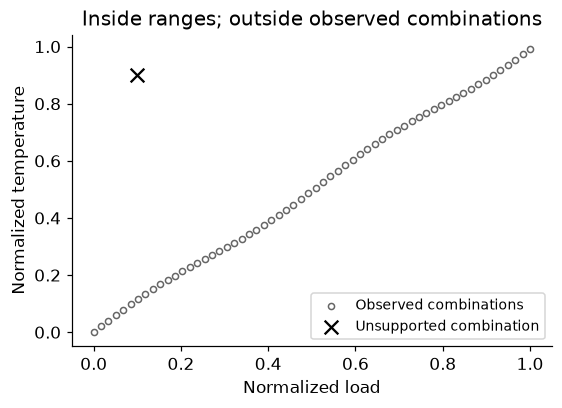

In [5]:
t=np.linspace(0,1,60);cloud=np.column_stack([t,t+.015*np.sin(12*t)]);q=np.array([.1,.9])
inside=bool(np.all((q>=cloud.min(0))&(q<=cloud.max(0))));distance=float(np.linalg.norm(cloud-q,axis=1).min())
assert inside and distance>.2
fig,ax=plt.subplots(figsize=(5,3.6));ax.scatter(*cloud.T,s=16,facecolors='white',edgecolors='.4',label='Observed combinations');ax.scatter(*q,marker='x',s=80,color='black',label='Unsupported combination')
ax.set(xlabel='Normalized load',ylabel='Normalized temperature',title='Inside ranges; outside observed combinations');ax.legend(fontsize=9);plt.show()
RESULTS['joint_support_query_distance']=distance


<a id="exercises"></a>
## Exercises and hints

1. Give buildings unequal reading counts and compare row-averaged MSE with the mean of site MSEs. Take the square root after averaging squared errors.
2. Add five calibration readings from each new building. Declare this as a third prediction contract and reserve later readings for evaluation.
3. Make building age shift for new construction. Explain why a group split within the original age range cannot establish transfer.
4. Compare the fixed rule with an intercept-free load model using development sites only; obtain fresh final sites for the selected rule.

**Hints:** the generalization unit, available information, loss and averaging population jointly define the claim. A row split is useful for the known-building question and inadequate for the new-building question. See the official [grouped cross-validation guide](https://scikit-learn.org/1.9/modules/cross_validation.html#cross-validation-iterators-for-grouped-data).


In [6]:
summary={'example_id':'code_022','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['known-site versus new-site estimands', 'row and group information boundaries', 'training-only site state', 'equal-site versus row averaging', 'joint support and extrapolation'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["known-site versus new-site estimands", "row and group information boundaries", "training-only site state", "equal-site versus row averaging", "joint support and extrapolation"], "elapsed_seconds": 0.126, "example_id": "code_022", "hardware": "Darwin arm64 CPU", "results": {"development_RMSE_known_new_mm": [0.07037735018635698, 0.7809324188664392], "final_RMSE_known_new_mm": [0.0811412695481926, 0.7891573160864884], "final_new_buildings": 6, "joint_support_query_distance": 0.566609891575695}, "seed": 522, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
